# Imports

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn import datasets, linear_model, model_selection
from sklearn.metrics import mean_squared_error

# Using BMI to predict disease risk

In [ ]:
# load the diabetes dataset
print(datasets.load_diabetes().data[0])
print(datasets.load_diabetes().target[0])
print(datasets.load_diabetes().feature_names)
X, y = datasets.load_diabetes(return_X_y=True)
print(f"X shape:{X.shape} \ny shape:{y.shape}")
print(f"First value of X: {X[0]} \nFirst value of y {y[0]}")


In [ ]:
X = X[:, 2]             # get only the 'bmi' column
print(X[0])
print(X.shape)
X = X.reshape((-1,1))
print(X[0])
print(X.shape)

In [ ]:
X_train, X_test, y_train, y_test = model_selection.train_test_split(
    X, y, 
    test_size=0.33
)

In [ ]:
model = linear_model.LinearRegression()
model.fit(X_train, y_train)

In [ ]:
y_pred = model.predict(X_test)
print(model.intercept_)
print(model.coef_)

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

train_mse = mean_squared_error(y_train, train_predictions)
test_mse = mean_squared_error(y_test, test_predictions)

train_mae = mean_absolute_error(y_train, train_predictions)
test_mae = mean_absolute_error(y_test, test_predictions)

print(f"Training MSE: {train_mse:.2f}")
print(f"Test MSE:     {test_mse:.2f}")
print(f"Training MAE: {train_mae:.2f}")
print(f"Test MAE:     {test_mae:.2f}")
print(f"Test R²:      {r2_score(y_test, test_predictions):.2f}")

In [ ]:
plt.scatter(X_test, y_test, color='black')
plt.plot(X_test, y_pred, color='blue', linewidth=3)
plt.xlabel('Scaled BMIs')
plt.ylabel('Disease Progression')
plt.title('A Graph Plot Showing Diabetes Progression Against BMI')
plt.show()

# Using all features to predict diabeties risk.

In [2]:
X, y = datasets.load_diabetes(return_X_y=True)

print(X.shape)
# (442, 10)

X_train, X_test, y_train, y_test = model_selection.train_test_split(
    X,
    y,
    test_size=0.33,
    random_state=42
)

model = linear_model.LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(model.intercept_)
print(model.coef_)

(442, 10)
150.43401223157832
[  32.14928032 -242.82449076  559.98996952  407.63766881 -718.69857577
  396.63703933   10.432395    171.81955335  627.07993787  -21.62312454]


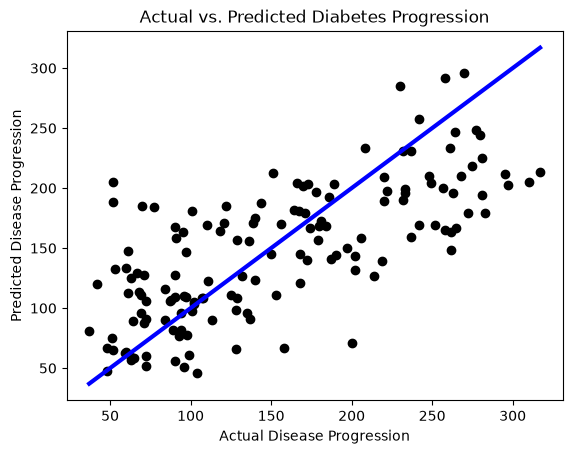

In [3]:
plt.scatter(y_test, y_pred, color="black")

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="blue",
    linewidth=3
)

plt.xlabel("Actual Disease Progression")
plt.ylabel("Predicted Disease Progression")
plt.title("Actual vs. Predicted Diabetes Progression")
plt.show()

In [6]:
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

train_mse = mean_squared_error(y_train, train_pred)
test_mse = mean_squared_error(y_test, test_pred)

print("Training MSE:", train_mse)
print("Test MSE:", test_mse)

Training MSE: 2949.2915737221497
Test MSE: 2817.808297221584
